In [24]:
# Evaluate and tune Gaussian Process hyperparameters
# 1 GPR model for each of the 3 target properties 
# Compare kernel settings using leave-one-out cross-validation (R²)
# Visualize 1D slices of the full GP by varying one ingredient while holding
# others constant, sampling 5 posterior functions

In [25]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

print()

In [26]:
# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
raw_data_summary = df[formula_cols + measured_target_cols].copy()
raw_data_summary[formula_cols] = raw_data_summary[formula_cols].fillna(0.0)
raw_data_summary[measured_target_cols] = raw_data_summary[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(raw_data_summary) == 25, (
    f"Expected the 25 original samples; found {len(raw_data_summary)}."
)
display(raw_data_summary)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.770000
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.120000
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.250000
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.330000
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.580000
5,8,3.0,0.0,0.0,0.0,0.202000,111.044347,27.400000
6,5,0.0,0.0,0.0,0.0,0.298930,56.958538,36.614852
7,5,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5,0.0,1.0,0.0,0.0,0.355557,44.308895,43.766577
9,5,0.0,2.0,0.0,0.0,0.358055,43.326301,44.186536


In [27]:
# Compare GPR kernel settings with leave-one-out cross-validation, then fit
# one selected Gaussian Process model for each target property.

import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm?)",
    "24h_avg_pct absorption": "24-hour absorption (%)",
    "24h_avg_pct_retention": "24-hour retention (%)",
}

model_data = df[feature_cols + target_cols].copy()
model_data[feature_cols] = model_data[feature_cols].fillna(0.0)
model_data[target_cols] = model_data[target_cols].apply(pd.to_numeric, errors="raise")
if model_data[target_cols].isna().any().any():
    raise ValueError("Target measurements contain missing values.")

X = model_data[feature_cols]
loo = LeaveOneOut()

# Raise the minimum length scale to encourage smoother fits; optimize within each fold.
def make_kernel_candidates(min_length_scale=1.0):
    return {
        "RBF": lambda: ConstantKernel(1.0, (1e-3, 1e3))
        * RBF(length_scale=np.ones(len(feature_cols)), length_scale_bounds=(min_length_scale, 1e5))
        + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e1)),
        "Mat?rn 1.5": lambda: ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(length_scale=np.ones(len(feature_cols)), length_scale_bounds=(min_length_scale, 1e5), nu=1.5)
        + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e1)),
        "Mat?rn 2.5": lambda: ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(length_scale=np.ones(len(feature_cols)), length_scale_bounds=(min_length_scale, 1e5), nu=2.5)
        + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e1)),
    }


def make_gpr(kernel, n_restarts_optimizer=0):
    return make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=n_restarts_optimizer,
            random_state=42,
        ),
    )


cv_rows = []
gpr_models = {}
best_cv_predictions = {}

for target in target_cols:
    y = model_data[target]
    min_length_scale = 1.0 if target in {"Avg_Density_g_cm3", "24h_avg_pct_retention"} else 3.0
    kernel_candidates = make_kernel_candidates(min_length_scale)
    predictions_by_kernel = {}
    for kernel_name, kernel_factory in kernel_candidates.items():
        oof_prediction = np.empty(len(model_data), dtype=float)
        for train_indices, test_indices in loo.split(X):
            model = make_gpr(kernel_factory())
            model.fit(X.iloc[train_indices], y.iloc[train_indices])
            oof_prediction[test_indices] = model.predict(X.iloc[test_indices])
        predictions_by_kernel[kernel_name] = oof_prediction
        cv_rows.append({
            "Property": target_labels[target],
            "Kernel": kernel_name,
            "LOOCV R?": r2_score(y, oof_prediction),
            "LOOCV MAE": mean_absolute_error(y, oof_prediction),
            "LOOCV RMSE": np.sqrt(mean_squared_error(y, oof_prediction)),
        })

    target_rows = [row for row in cv_rows if row["Property"] == target_labels[target]]
    best_result = max(target_rows, key=lambda row: row["LOOCV R?"])
    best_cv_predictions[target] = predictions_by_kernel[best_result["Kernel"]]
    gpr_models[target] = make_gpr(kernel_candidates[best_result["Kernel"]]()).fit(X, y)

# Save the fitted models as a dictionary keyed by the target column name.
import joblib

models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "gpr_models.joblib"
joblib.dump(gpr_models, model_path)
print(f"Saved {len(gpr_models)} target-specific GPR models to {model_path}")

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["Property", "LOOCV R?"], ascending=[True, False]
).reset_index(drop=True)
print("LOOCV comparison (higher R? is better):")
display(cv_results.round(4))

best_model_summary = []
for target in target_cols:
    target_results = cv_results.loc[cv_results["Property"] == target_labels[target]]
    selected = target_results.loc[target_results["LOOCV R?"].idxmax()]
    fitted_gpr = gpr_models[target].named_steps["gaussianprocessregressor"]
    length_scales = dict(zip(
        feature_cols,
        np.atleast_1d(fitted_gpr.kernel_.k1.k2.length_scale).tolist(),
    ))
    print(f"{target_labels[target]} optimized length scales (standardized feature units): {length_scales}")
    best_model_summary.append({
        "Property": target_labels[target],
        "Selected kernel": selected["Kernel"],
        "Minimum length-scale bound": 1.0 if target in {"Avg_Density_g_cm3", "24h_avg_pct_retention"} else 3.0,
        "LOOCV R?": selected["LOOCV R?"],
        "Optimized kernel (all samples)": str(fitted_gpr.kernel_),
    })
print("Selected model for each property, refit on all samples:")
display(pd.DataFrame(best_model_summary))


c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages

Saved 3 target-specific GPR models to C:\Users\Brooke\Foam project\models\gpr_models.joblib
LOOCV comparison (higher R? is better):


c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1.0. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages

,Property,Kernel,LOOCV R?,LOOCV MAE,LOOCV RMSE
0,24-hour absorption (%),Mat?rn 2.5,0.9047,18.9191,23.9591
1,24-hour absorption (%),RBF,0.8988,19.5841,24.6984
2,24-hour absorption (%),Mat?rn 1.5,0.8804,21.3048,26.8460
3,24-hour retention (%),Mat?rn 2.5,0.7220,5.5910,6.8404
4,24-hour retention (%),Mat?rn 1.5,0.7150,5.4357,6.9251
5,24-hour retention (%),RBF,0.6883,6.0717,7.2427
6,Average density (g/cm?),RBF,0.8954,0.0170,0.0207
7,Average density (g/cm?),Mat?rn 2.5,0.8629,0.0190,0.0237
8,Average density (g/cm?),Mat?rn 1.5,0.8577,0.0191,0.0241


Average density (g/cm?) optimized length scales (standardized feature units): {'TEM': 1.0, 'Joncryl': 1.0, 'NC513': 1.2075191669506218, 'PEG-DE': 27627.27198402014, 'NGDE': 3.5245784836875527}
24-hour absorption (%) optimized length scales (standardized feature units): {'TEM': 6.913506117130441, 'Joncryl': 10.6343702859014, 'NC513': 100000.00000000001, 'PEG-DE': 3.0000000000000004, 'NGDE': 21.984250795680985}
24-hour retention (%) optimized length scales (standardized feature units): {'TEM': 1.0, 'Joncryl': 1.0, 'NC513': 1.3475126302173814, 'PEG-DE': 2.156560832822897, 'NGDE': 10.43650428143172}
Selected model for each property, refit on all samples:


,Property,Selected kernel,Minimum length-scale bound,LOOCV R?,Optimized kernel (all samples)
0,Average density (g/cm?),RBF,1.0,0.895404,"0.988**2 * RBF(length_scale=[1, 1, 1.21, 2.76e..."
1,24-hour absorption (%),Mat?rn 2.5,3.0,0.904730,"2.21**2 * Matern(length_scale=[6.91, 10.6, 1e+..."
2,24-hour retention (%),Mat?rn 2.5,1.0,0.721956,"1.17**2 * Matern(length_scale=[1, 1, 1.35, 2.1..."


Fixed ingredient values:


,Fixed value
TEM,8.0
NC513,0.0
PEG-DE,0.0
NGDE,0.0


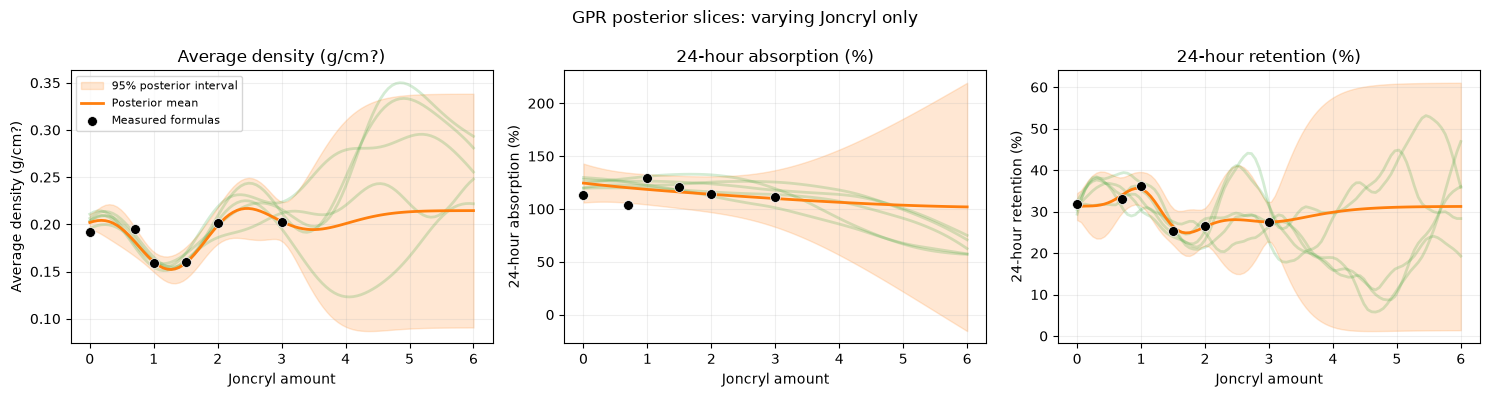

In [28]:
import matplotlib.pyplot as plt

# Select formulas where Joncryl is the only ingredient that varies.
fixed_cols = [col for col in feature_cols if col != "Joncryl"]
fixed_values = X.iloc[0][fixed_cols]
same_formula = np.isclose(X[fixed_cols], fixed_values).all(axis=1)
joncryl_data = X.loc[same_formula]

if len(joncryl_data) != 6:
    raise ValueError(
        f"Expected 6 formulas with only Joncryl varying; found {len(joncryl_data)}."
    )

baseline_formula = joncryl_data.iloc[0].copy()
print("Fixed ingredient values:")
display(fixed_values.to_frame("Fixed value"))

n_grid = 100
n_posterior_samples = 5
rng = np.random.default_rng(42)
joncryl_grid = np.linspace(0.0, 6.0, n_grid)

grid_data = pd.DataFrame(
    np.repeat(baseline_formula.to_numpy()[None, :], n_grid, axis=0),
    columns=feature_cols,
)
grid_data["Joncryl"] = joncryl_grid

fig, axes = plt.subplots(1, len(target_cols), figsize=(15, 4), squeeze=False)

for col, target in enumerate(target_cols):
    axis = axes[0, col]
    pipeline = gpr_models[target]
    scaled_grid = pipeline.named_steps["standardscaler"].transform(grid_data)
    gpr = pipeline.named_steps["gaussianprocessregressor"]
    mean, covariance = gpr.predict(scaled_grid, return_cov=True)

    target_scale = model_data[target].std(ddof=0)
    if target_scale == 0:
        target_scale = 1.0
    observation_noise = gpr.kernel_.k2.noise_level * target_scale**2
    covariance -= observation_noise * np.eye(n_grid)
    covariance = (covariance + covariance.T) / 2

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    covariance_factor = eigenvectors * np.sqrt(np.clip(eigenvalues, 0, None))
    posterior_samples = (
        mean[:, None]
        + covariance_factor @ rng.standard_normal((n_grid, n_posterior_samples))
    )

    for sample_index in range(n_posterior_samples):
        axis.plot(
            joncryl_grid,
            posterior_samples[:, sample_index],
            color="tab:green",
            alpha=0.20,
            linewidth=2,
        )

    posterior_std = np.sqrt(np.clip(np.diag(covariance), 0, None))
    axis.fill_between(
        joncryl_grid,
        mean - 1.96 * posterior_std,
        mean + 1.96 * posterior_std,
        color="tab:orange",
        alpha=0.18,
        label="95% posterior interval",
    )
    axis.plot(
        joncryl_grid, mean, color="tab:orange", linewidth=2, label="Posterior mean"
    )
    axis.scatter(
        joncryl_data["Joncryl"],
        model_data.loc[joncryl_data.index, target],
        color="black",
        edgecolor="white",
        linewidth=0.5,
        s=50,
        zorder=5,
        label="Measured formulas",
    )

    axis.set_title(target_labels[target])
    axis.set_xlabel("Joncryl amount")
    axis.set_ylabel(target_labels[target])
    axis.grid(alpha=0.2)
    if col == 0:
        axis.legend(loc="best", fontsize=8)

fig.suptitle("GPR posterior slices: varying Joncryl only")
fig.tight_layout()
plt.show()